# Исследование данных для рекомендательной системы книг

## 0. Постановка исследования

### 0.1. Постановка задачи

**Цель проекта**: разработать рекомендательную систему книг и сравнить содержательный, коллаборативный и гибридный подходы для формирования персональных рекомендаций.

Содержательный подход использует описания и характеристики книг. Коллаборативный учитывает пользовательские оценки. Гибридный подход объединяет информацию о книгах и взаимодействиях пользователей.

В исследовании необходимо проверить качество исходных данных, подготовить связанные таблицы книг и взаимодействий, определить протокол оценки и сравнить рекомендательные модели.

### 0.2. Источники данных

Используются три исходных файла из двух открытых источников:

1. `datasets1.parquet`: каталог книг из набора
   [euclaise/goodreads_100k](https://huggingface.co/datasets/euclaise/goodreads_100k).
2. `datasets2.csv`: метаданные произведений из набора
   [Pauleera/Goodreads-Book-Reviews](https://huggingface.co/datasets/Pauleera/Goodreads-Book-Reviews).
3. `reviews.csv`: пользовательские отзывы и оценки из того же источника.

Названия полей, типы данных и связи между таблицами будут проверены
после загрузки.

### 0.3. План исследования данных

1. Загрузка и первичный обзор таблиц.
2. Проверка идентификаторов, пропусков и дубликатов.
3. Анализ описаний и характеристик книг.
4. Анализ пользовательских оценок и активности.
5. Проверка связей между источниками.
6. Обоснование очистки и объединения данных.

## 1. Подготовка среды и предварительный обзор

### 1.1. Загрузка библиотек

При отсутствии необходимых библиотек в окружении проекта для правильной работы исследования рекомендуется выполнение следующей ячейки:

In [1]:
%pip install pandas pyarrow matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


`%pip` устанавливает необходимые пакеты в окружение текущего ядра. Если после установки появляется просьба перезапуска ядра, перезапустите его перед выполнением следующих ячеек.

### 1.2. Подготовка среды

Подключим библиотеки, настроим отображение таблиц и зафиксируем версии основных пакетов.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib
import pyarrow
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

versions = pd.Series(
    {
        "Python": sys.version.split()[0],
        "pandas": pd.__version__,
        "seaborn": sns.__version__,
        "pyarrow": pyarrow.__version__,
        "matplotlib": matplotlib.__version__,
    },
    name="version",
)

versions.to_frame()

,version
Python,3.13.2
pandas,3.0.5
seaborn,0.13.2
pyarrow,25.0.1
matplotlib,3.11.1


### 1.3. Расположение исходных файлов

Проверим наличие файлов и их размеры перед загрузкой. Исходные данные остаются без изменений.

In [3]:
current_dir = Path.cwd()

if (current_dir / "data" / "raw").is_dir():
    project_dir = current_dir
elif (current_dir.parent / "data" / "raw").is_dir():
    project_dir = current_dir.parent
else:
    raise FileNotFoundError(
        "Не найдена папка data/raw. "
        "Проверьте структуру проекта и рабочую папку ноутбука."
    )

raw_dir = project_dir / "data" / "raw"

paths = {
    "books_texts": raw_dir / "datasets1.parquet",
    "books_metadata": raw_dir / "datasets2.csv",
    "reviews": raw_dir / "reviews.csv",
}

file_summary = pd.DataFrame(
    [
        {
            "Таблица": name,
            "Файл": path.name,
            "Наличие": path.is_file(),
            "Размер, МиБ": (
                round(path.stat().st_size / 1024**2, 2)
                if path.is_file()
                else None
            ),
        }
        for name, path in paths.items()
    ]
)

file_summary

,Таблица,Файл,Наличие,"Размер, МиБ"
0,books_texts,datasets1.parquet,True,66.39
1,books_metadata,datasets2.csv,True,15.44
2,reviews,reviews.csv,True,1317.24


In [4]:
missing_files = [
    path.name
    for path in paths.values()
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Не найдены исходные файлы: " + ", ".join(missing_files)
    )

print("Все исходные файлы найдены.")

Все исходные файлы найдены.


### 1.4. Предварительный анализ структуры файлов

Проверим схему Parquet и названия столбцов CSV перед полной загрузкой.

На этапе предварительного просмотра значения CSV читаются как строки.
Это позволяет сохранить исходное представление идентификаторов,
включая ведущие нули в ISBN. Числовые поля и даты будут преобразованы
отдельно после проверки их содержимого.

In [5]:
parquet_file = pq.ParquetFile(paths["books_texts"])

print(
    "Число строк в первой таблице:",
    f"{parquet_file.metadata.num_rows:,}".replace(",", " "),
)

parquet_schema = pd.DataFrame(
    [
        {
            "Столбец": field.name,
            "Тип в файле": str(field.type),
        }
        for field in parquet_file.schema_arrow
    ]
)

parquet_schema

Число строк в первой таблице: 100 000


,Столбец,Тип в файле
0,author,string
1,desc,string
2,genre,string
3,isbn,string
4,link,string
5,pages,int64
6,rating,double
7,reviews,int64
8,title,string
9,totalratings,int64


Здесь мы читаем метаданные файла, а не загружаем всю таблицу в память.

Важно проверить тип ISBN в самом Parquet: если ведущие нули были потеряны ещё при создании файла, простое преобразование в строку их не восстановит.

In [6]:
metadata_preview = pd.read_csv(
    paths["books_metadata"],
    nrows=5,
    dtype="string",
    keep_default_na=False,
)

reviews_preview = pd.read_csv(
    paths["reviews"],
    nrows=5,
    dtype="string",
    keep_default_na=False,
)

print("Столбцы таблицы метаданных:")
print(metadata_preview.columns.tolist())

print("\nСтолбцы таблицы отзывов:")
print(reviews_preview.columns.tolist())

Столбцы таблицы метаданных:
['work_id', 'isbn', 'isbn13', 'original_title', 'author', 'original_publication_year', 'num_pages', 'description', 'genres', 'image_url', 'reviews_count', 'text_reviews_count', '5_star_ratings', '4_star_ratings', '3_star_ratings', '2_star_ratings', '1_star_ratings', 'ratings_count', 'avg_rating', 'similar_books']

Столбцы таблицы отзывов:
['review_id', 'user_id', 'work_id', 'started_at', 'read_at', 'date_added', 'rating', 'review_text', 'n_votes', 'n_comments']


`keep_default_na=False` пока сохраняет исходные текстовые обозначения пропусков. Например, строка `"NA"` не будет автоматически превращена в отсутствующее значение. Правила обработки пропусков зададим после знакомства с содержимым.

In [7]:
metadata_preview

,work_id,isbn,isbn13,original_title,author,original_publication_year,num_pages,description,genres,image_url,reviews_count,text_reviews_count,5_star_ratings,4_star_ratings,3_star_ratings,2_star_ratings,1_star_ratings,ratings_count,avg_rating,similar_books
0,2919130,1416534601,9781416534600,Nocturnes,John Connolly,2004,,,"fiction, fantasy, paranormal, mystery, thriller, crime, young-adult",https://s.gr-assets.com/assets/nophoto/book/111x148-bcc042a9c91a29c1d680899eff700a03.png,8820,338,1118,1601,1029,190,58,3996,3.9,
1,52087333,,,Draw Play,Tia Lewis,2016,,Jake:\nI can't believe my coach assigned me a tutor. I'm all that on the field and between the sheets -- who cares a...,"romance, fiction",https://s.gr-assets.com/assets/nophoto/book/111x148-bcc042a9c91a29c1d680899eff700a03.png,2482,204,204,353,274,77,29,937,3.7,
2,1649583,1416505520,9781416505525,Citizen of the Galaxy,Robert A. Heinlein,1957,,"In a distant galaxy, the atrocity of slavery was alive and well, and young Thorby was just another orphaned boy sold...","fiction, young-adult, fantasy, paranormal, children",https://s.gr-assets.com/assets/nophoto/book/111x148-bcc042a9c91a29c1d680899eff700a03.png,16506,447,3539,4351,2863,444,53,11250,4,
3,688299,0060541830,9780060541835,Congo,Michael Crichton,1980,,"Deep in the African rain forest, near the legendary ruins of the Lost City of Zinj, an expedition of eight American ...","fiction, mystery, thriller, crime, fantasy, paranormal",https://s.gr-assets.com/assets/nophoto/book/111x148-bcc042a9c91a29c1d680899eff700a03.png,170916,1633,25081,45775,48505,14001,2926,136288,3.6,
4,3464264,0451528824,9780451528827,Anne of Green Gables,L.M. Montgomery,1908,,"Everyone's favorite redhead, the spunky Anne Shirley, begins her adventures at Green Gables, a farm outside Avonlea,...","fiction, young-adult, children, history, historical fiction, biography, romance",https://s.gr-assets.com/assets/nophoto/book/111x148-bcc042a9c91a29c1d680899eff700a03.png,743392,14586,272952,161856,81578,19933,9099,545418,4.2,


In [8]:
reviews_preview

,review_id,user_id,work_id,started_at,read_at,date_added,rating,review_text,n_votes,n_comments
0,fa7a00c01296e3b2b2e857d79c51ea77,3693bb4f1062b659a354848cf11ca313,6128277,,,2013-12-21 00:00:00.000,5,"Fire is half-human and half monster. Monsters in these lands are beautiful, very bright and colorful and usually hav...",0,0
1,de0f7c8d15e247443e51969becf2878e,3693bb4f1062b659a354848cf11ca313,3270810,,,2013-12-21 00:00:00.000,5,"Katsa is a graceling - blessed with an ability (in her case, ability to kill easily) that marks her as different. He...",0,0
2,e79b49504ef58b2defcdc8b79e2ec3fb,3693bb4f1062b659a354848cf11ca313,4768235,,,2013-12-19 00:00:00.000,5,"This is a fun, light-hearted read. Tammy Jo is having a bad week, a really bad week and despite her lack of magical ...",0,0
3,495c1210a9dbd819cbf7717dfb8b217f,3693bb4f1062b659a354848cf11ca313,6264661,,,2013-12-16 00:00:00.000,5,"Cassel, was a character that I was looking forward to and grew on me as the book grew to and end. He starts out as a...",0,0
4,54fcd8963c9dd56485d2a4ad152699c2,3693bb4f1062b659a354848cf11ca313,3429537,,,2013-12-16 00:00:00.000,5,This is kind of one of those books that I saw getting popular back with it first came out; many good reviews were po...,0,0


In [9]:
first_batch = next(
    parquet_file.iter_batches(batch_size=5),
    None,
)

if first_batch is not None:
    books_preview = first_batch.to_pandas()
else:
    books_preview = pd.DataFrame(
        columns=parquet_file.schema_arrow.names
    )

books_preview

,author,desc,genre,isbn,link,pages,rating,reviews,title,totalratings
0,Laurence M. Hauptman,Reveals that several hundred thousand Indians were affected by the Civil War and that twenty thousand Indians enlist...,"History,Military History,Civil War,American History,American Civil War,Nonfiction,North American Hi...,American Hist...",002914180X,https://goodreads.com/book/show/1001053.Between_Two_Fires,0,3.52,5,Between Two Fires: American Indians in the Civil War,33
1,"Charlotte Fiell,Emmanuelle Dirix",Fashion Sourcebook - 1920s is the first book in a brand-new series by Fiell Publishing that documents comprehensivel...,"Couture,Fashion,Historical,Art,Nonfiction",1906863482,https://goodreads.com/book/show/10010552-fashion-sourcebook-1920s,576,4.51,6,Fashion Sourcebook 1920s,41
2,Andy Anderson,"The seminal history and analysis of the Hungarian Revolution and the workers' councils, perhaps the single most impo...","Politics,History",948984147,https://goodreads.com/book/show/1001077.Hungary_56,124,4.15,2,Hungary 56,26
3,Carlotta R. Anderson,"""All-American Anarchist"" chronicles the life and work of Joseph A. Labadie (1850-1933), Detroit's prominent labor or...","Labor,History",814327079,https://goodreads.com/book/show/1001079.All_American_Anarchist,324,3.83,1,All-American Anarchist: Joseph A. Labadie and the Labor Movement,6
4,Jean Leveille,"Aujourdâ€™hui, lâ€™oiseau nous invite Ã sa table, table surprenante par sa diversitÃ© et son originalitÃ©. Tous ini...",NaN,2761920813,https://goodreads.com/book/show/10010880-les-oiseaux-gourmands,177,4.00,1,Les oiseaux gourmands,1


### 1.5. Результаты предварительного просмотра

Все три исходных файла найдены и доступны для чтения. Первый каталог
содержит 100 000 записей и 10 столбцов. Вторая таблица содержит
20 столбцов с метаданными произведений, третья - 10 столбцов
с пользовательскими отзывами.

Описания книг присутствуют в обоих каталогах. Таблицы метаданных
и отзывов содержат поле work_id, которое необходимо проверить
перед использованием для объединения. Для сопоставления двух
каталогов доступны ISBN.

В просмотренных записях обнаружены короткие ISBN, пример нарушенной
кодировки, нулевое число страниц и ссылки на заглушки обложек.
Распространённость этих особенностей требует проверки на полных
таблицах.

Размер файла отзывов составляет около 1,29 ГиБ. Для первоначального
анализа взаимодействий будут загружены все записи, но без текстов
отзывов. Исходный файл остаётся без изменений.

## 2. Загрузка и первичная проверка данных

### 2.1. Загрузка каталогов книг

Загрузим оба каталога целиком. В CSV сохраним исходное строковое
представление значений. Преобразование числовых полей выполним
после проверки содержимого.

In [10]:
books_texts = pd.read_parquet(paths["books_texts"])

books_metadata = pd.read_csv(
    paths["books_metadata"],
    dtype="string",
    keep_default_na=False,
)

print("Первый каталог:", books_texts.shape)
print("Метаданные произведений:", books_metadata.shape)

Первый каталог: (100000, 10)
Метаданные произведений: (13525, 20)


### 2.2. Загрузка пользовательских взаимодействий

Загрузим идентификаторы, оценки, даты и счётчики реакций.
Тексты отзывов пока не включаем в рабочую таблицу: они не нужны
для первоначального анализа структуры взаимодействий.

Чтение ограничивается столбцами, но не количеством записей.

In [11]:
review_columns = [
    "review_id",
    "user_id",
    "work_id",
    "started_at",
    "read_at",
    "date_added",
    "rating",
    "n_votes",
    "n_comments",
]

reviews = pd.read_csv(
    paths["reviews"],
    usecols=review_columns,
    dtype="string",
    keep_default_na=False,
)

print("Таблица взаимодействий:", reviews.shape)

Таблица взаимодействий: (1143887, 9)


Чтение всё равно требует обработки большого CSV, поэтому эта ячейка может выполняться заметно дольше предыдущей. Мы сокращаем прежде всего объём данных в оперативной памяти.

### 2.3. Размеры таблиц и использование памяти

In [12]:
tables = {
    "books_texts": books_texts,
    "books_metadata": books_metadata,
    "reviews": reviews,
}

table_summary = pd.DataFrame(
    [
        {
            "Таблица": name,
            "Строки": len(df),
            "Столбцы": df.shape[1],
            "Память, МиБ": round(
                df.memory_usage(deep=True).sum() / 1024**2,
                2,
            ),
        }
        for name, df in tables.items()
    ]
)

table_summary

,Таблица,Строки,Столбцы,"Память, МиБ"
0,books_texts,100000,10,109.08
1,books_metadata,13525,20,17.04
2,reviews,1143887,9,225.09


Размер файла и занимаемая таблицей память могут существенно различаться. Здесь измеряем именно память загруженного DataFrame.

### 2.4. Пропуски и пустые значения

Для каждого столбца отдельно подсчитаем системные пропуски
и строки, которые становятся пустыми после удаления крайних пробелов.

Проверка не изменяет исходные таблицы. Текстовые обозначения
вроде `"null"` и `"N/A"` на данном этапе автоматически не заменяются.

In [13]:
def missing_report(df):
    rows = []

    for column in df.columns:
        values = df[column]
        missing_count = int(values.isna().sum())

        empty_count = 0

        if (
            pd.api.types.is_object_dtype(values.dtype)
            or pd.api.types.is_string_dtype(values.dtype)
        ):
            empty_count = int(
                values.astype("string")
                .str.strip()
                .eq("")
                .fillna(False)
                .sum()
            )

        total_missing = missing_count + empty_count

        rows.append(
            {
                "Столбец": column,
                "Тип": str(values.dtype),
                "Системные пропуски": missing_count,
                "Пустые строки": empty_count,
                "Всего отсутствует": total_missing,
                "Доля, %": (
                    round(total_missing / len(df) * 100, 2)
                    if len(df)
                    else float("nan")
                ),
            }
        )

    return (
        pd.DataFrame(rows)
        .sort_values("Доля, %", ascending=False)
        .reset_index(drop=True)
    )

In [14]:
missing_books_texts = missing_report(books_texts)
missing_books_texts

,Столбец,Тип,Системные пропуски,Пустые строки,Всего отсутствует,"Доля, %"
0,isbn,str,14482,0,14482,14.48
1,genre,str,10467,0,10467,10.47
2,desc,str,6772,0,6772,6.77
3,author,str,0,0,0,0.00
4,link,str,0,0,0,0.00
5,pages,int64,0,0,0,0.00
6,rating,float64,0,0,0,0.00
7,reviews,int64,0,0,0,0.00
8,title,str,1,0,1,0.00
9,totalratings,int64,0,0,0,0.00


In [15]:
missing_books_metadata = missing_report(books_metadata)
missing_books_metadata

,Столбец,Тип,Системные пропуски,Пустые строки,Всего отсутствует,"Доля, %"
0,similar_books,string,0,2515,2515,18.60
1,isbn,string,0,2051,2051,15.16
2,isbn13,string,0,1661,1661,12.28
3,num_pages,string,0,730,730,5.40
4,description,string,0,169,169,1.25
5,original_publication_year,string,0,18,18,0.13
6,original_title,string,0,0,0,0.00
7,work_id,string,0,0,0,0.00
8,genres,string,0,0,0,0.00
9,image_url,string,0,0,0,0.00


In [16]:
missing_reviews = missing_report(reviews)
missing_reviews

,Столбец,Тип,Системные пропуски,Пустые строки,Всего отсутствует,"Доля, %"
0,started_at,string,0,347495,347495,30.38
1,read_at,string,0,112122,112122,9.80
2,rating,string,0,37318,37318,3.26
3,review_id,string,0,0,0,0.00
4,work_id,string,0,0,0,0.00
5,user_id,string,0,0,0,0.00
6,date_added,string,0,0,0,0.00
7,n_votes,string,0,0,0,0.00
8,n_comments,string,0,0,0,0.00


### 2.5. Первичная проверка идентификаторов

Проверим заполненность и повторяемость ключевых полей.

При проверке временно убираем пробелы по краям идентификаторов.
Исходные столбцы не изменяем. Повторы пока не удаляем:
их смысл зависит от назначения таблицы.

In [17]:
def key_report(df, columns):
    rows = []

    for column in columns:
        values = df[column].astype("string").str.strip()

        missing_mask = values.isna() | values.eq("").fillna(False)
        valid_values = values[~missing_mask]

        rows.append(
            {
                "Поле": column,
                "Отсутствует": int(missing_mask.sum()),
                "Уникальных непустых": valid_values.nunique(),
                "Строк сверх первого вхождения": int(
                    valid_values.duplicated().sum()
                ),
                "Строк в повторяющихся группах": int(
                    valid_values.duplicated(keep=False).sum()
                ),
            }
        )

    return pd.DataFrame(rows)

In [18]:
key_report(books_texts, ["isbn", "link"])

,Поле,Отсутствует,Уникальных непустых,Строк сверх первого вхождения,Строк в повторяющихся группах
0,isbn,14482,85518,0,0
1,link,0,100000,0,0


In [19]:
key_report(books_metadata, ["work_id", "isbn", "isbn13"])

,Поле,Отсутствует,Уникальных непустых,Строк сверх первого вхождения,Строк в повторяющихся группах
0,work_id,0,13525,0,0
1,isbn,2051,11474,0,0
2,isbn13,1661,11864,0,0


In [20]:
key_report(reviews, ["review_id", "user_id", "work_id"])

,Поле,Отсутствует,Уникальных непустых,Строк сверх первого вхождения,Строк в повторяющихся группах
0,review_id,0,1143887,0,0
1,user_id,0,18800,1125087,1143417
2,work_id,0,13525,1130362,1143887


Разница между двумя последними показателями такая: для значений А, А, А, Б число строк сверх первого вхождения равно 2, а число строк в повторяющейся группе равно 3.

### 2.6. Исходные значения пользовательских оценок

Проверим частоты исходных значений `rating` перед преобразованием
в числовой формат. Нулевые, пустые и нестандартные значения
пока сохраняются.

In [21]:
rating_counts = (
    reviews["rating"]
    .value_counts(dropna=False)
    .rename_axis("Исходное значение")
    .reset_index(name="Количество")
)

rating_counts["Доля, %"] = (
    rating_counts["Количество"] / len(reviews) * 100
).round(2)

rating_counts

,Исходное значение,Количество,"Доля, %"
0,4,396722,34.68
1,5,336246,29.4
2,3,242109,21.17
3,2,94030,8.22
4,1,37462,3.27
5,,37318,3.26


### 2.7. Выводы по загрузке и первичной проверке данных

**Объём данных**

Загружены три таблицы: первый каталог содержит 100 000 записей
и 10 столбцов, таблица метаданных содержит 13 525 записей
и 20 столбцов, таблица пользовательских взаимодействий содержит
1 143 887 записей и 9 выбранных столбцов.

Из файла отзывов загружены все записи, но исключён столбец
review_text. Для первоначальной проверки взаимодействий достаточно
идентификаторов, оценок, дат и счётчиков реакций. Тексты отзывов
сохранены в исходном файле и при необходимости могут быть
исследованы отдельно.

Объём памяти, занимаемый тремя DataFrame по результатам
memory_usage(deep=True), составляет около 351,21 МиБ.
Это значение не включает всю память процесса Python и временные
объекты, возникающие при вычислениях.

**Заполненность первого каталога**

В первом каталоге отсутствуют 14 482 ISBN (14,48%),
10 467 значений жанра (10,47%) и 6 772 описания (6,77%).
Также обнаружена одна запись без названия. В остальных полях
системные пропуски и пустые строки не выявлены.

Отсутствие формальных пропусков не гарантирует корректность
значений. В дальнейшем необходимо проверить нулевые значения
числа страниц, качество текстов и возможные текстовые
обозначения отсутствующих данных.

Все 85 518 непустых ISBN уникальны после удаления крайних
пробелов при проверке. Все 100 000 ссылок также заполнены
и уникальны. При этом уникальность ISBN не подтверждает
правильность их формата, а уникальность ссылок не исключает
наличия разных изданий одного произведения.

**Заполненность метаданных произведений**

В таблице метаданных отсутствуют 169 описаний (1,25%).
Это существенно меньшая доля, чем в первом каталоге,
но качество самих текстов ещё не оценивалось.

Поле isbn не заполнено в 2 051 записи (15,16%),
isbn13 в 1 661 записи (12,28%). Эти группы могут пересекаться:
число произведений без обоих идентификаторов необходимо
рассчитать отдельно.

Число страниц отсутствует в 730 записях (5,40%),
год первой публикации в 18 записях (0,13%),
список similar_books в 2 515 записях (18,60%).

Все 13 525 значений work_id заполнены и уникальны.
Повторы среди непустых isbn и isbn13 не обнаружены.
Это позволяет рассматривать work_id как ключ таблицы,
однако соответствие идентификаторов между источниками
требует отдельной проверки.

**Структура пользовательских взаимодействий**

Таблица взаимодействий содержит 18 800 уникальных пользователей
и 13 525 уникальных идентификаторов произведений.
Все 1 143 887 значений review_id заполнены и уникальны.

Повторение user_id и work_id ожидаемо: один пользователь
может взаимодействовать с несколькими произведениями,
а одно произведение может получать отзывы разных пользователей.
Повторные сочетания user_id и work_id на данном этапе
ещё не исследовались.

Число уникальных work_id во взаимодействиях совпадает
с числом произведений в метаданных. Однако совпадение
количеств не доказывает равенство наборов идентификаторов.
Перед объединением необходимо проверить ссылки между таблицами.

**Оценки пользователей**

В поле rating обнаружены значения от 1 до 5 и пустые строки.
Пустая оценка присутствует в 37 318 взаимодействиях (3,26%).

Наиболее распространена оценка 4: 396 722 записи (34,68%).
Оценка 5 встречается в 336 246 записях (29,40%).
Вместе оценки 4 и 5 составляют 64,08% всех взаимодействий
и 66,24% взаимодействий с заполненной оценкой.

Таким образом, в наблюдаемых данных преобладают высокие оценки.
Это необходимо учитывать при определении положительных
взаимодействий и интерпретации качества рекомендаций.
Распределение характеризует представленные в датасете отзывы
и не описывает отношение пользователей ко всем книгам каталога.

Пустые оценки пока сохраняются. Они не трактуются как нулевые
или отрицательные: запись подтверждает наличие отзыва,
но не содержит явной числовой оценки предпочтения.

**Даты взаимодействий**

Дата начала чтения started_at отсутствует в 347 495 записях
(30,38%), дата завершения чтения read_at в 112 122 записях
(9,80%). Поле date_added заполнено во всех записях.

Полнота date_added позволяет рассматривать его для временного
анализа. Однако сначала необходимо проверить преобразование
значений в даты, их диапазон и смысл. Дата добавления записи
не обязательно совпадает с датой чтения или выставления оценки.

**Дальнейшие действия**

На следующем этапе необходимо проверить:

1. Текстовые обозначения пропусков и корректность числовых полей.
2. Форматы и контрольные цифры ISBN.
3. Повторные пары пользователя и произведения.
4. Соответствие work_id между метаданными и взаимодействиями.
5. Форматы, диапазоны и заполненность преобразованных дат.

Объединение, удаление записей и заполнение пропусков пока
не выполнялись. Правила обработки будут определены
по результатам дополнительных проверок.

## 3. Проверка связей и повторных взаимодействий

Цель этапа: проверить соответствие произведений в метаданных
и отзывах, а также выявить повторные взаимодействия одного
пользователя с одним произведением.

Равенство количества уникальных идентификаторов не гарантирует
совпадения самих идентификаторов. Уникальность review_id
также не исключает нескольких отзывов для одной пары
пользователя и произведения.

Проверки выполняются без удаления записей и изменения
исходных таблиц.

### 3.1. Подготовка идентификаторов

Для проверки связей приведём идентификаторы к строковому
представлению и удалим пробелы по краям. Пустые значения
обозначим как пропуски.

Созданные объекты используются для диагностики.
Исходные таблицы остаются без изменений.

In [22]:
def prepare_identifier(series):
    values = series.astype("string").str.strip()
    return values.mask(values.eq(""), pd.NA)


metadata_work_ids = prepare_identifier(
    books_metadata["work_id"]
)

interaction_keys = pd.DataFrame(
    {
        "user_id": prepare_identifier(reviews["user_id"]),
        "work_id": prepare_identifier(reviews["work_id"]),
    },
    index=reviews.index,
)

interaction_keys.head()

,user_id,work_id
0,3693bb4f1062b659a354848cf11ca313,6128277
1,3693bb4f1062b659a354848cf11ca313,3270810
2,3693bb4f1062b659a354848cf11ca313,4768235
3,3693bb4f1062b659a354848cf11ca313,6264661
4,3693bb4f1062b659a354848cf11ca313,3429537


### 3.2. Соответствие произведений между таблицами

Сравним множества непустых work_id в метаданных
и пользовательских взаимодействиях.

Определим число общих произведений, произведений без метаданных
и произведений без взаимодействий.

In [23]:
metadata_ids = set(metadata_work_ids.dropna())

review_ids = set(
    interaction_keys["work_id"].dropna()
)

common_ids = metadata_ids & review_ids
ids_without_metadata = review_ids - metadata_ids
ids_without_reviews = metadata_ids - review_ids

link_summary = pd.DataFrame(
    {
        "Показатель": [
            "Произведения в метаданных",
            "Произведения во взаимодействиях",
            "Общие произведения",
            "Произведения без метаданных",
            "Произведения без взаимодействий",
            "Наборы идентификаторов совпадают",
        ],
        "Значение": [
            len(metadata_ids),
            len(review_ids),
            len(common_ids),
            len(ids_without_metadata),
            len(ids_without_reviews),
            metadata_ids == review_ids,
        ],
    }
)

link_summary

,Показатель,Значение
0,Произведения в метаданных,13525
1,Произведения во взаимодействиях,13525
2,Общие произведения,13525
3,Произведения без метаданных,0
4,Произведения без взаимодействий,0
5,Наборы идентификаторов совпадают,True


### 3.3. Взаимодействия без метаданных

Подсчитаем записи с отсутствующим work_id и записи,
для которых непустой work_id не найден в таблице метаданных.
Эти ситуации учитываются отдельно.

In [24]:
missing_work_mask = interaction_keys["work_id"].isna()

unknown_work_mask = (
    ~missing_work_mask
    & ~interaction_keys["work_id"].isin(metadata_ids)
)

matched_work_mask = (
    ~missing_work_mask
    & interaction_keys["work_id"].isin(metadata_ids)
)

interaction_link_summary = pd.DataFrame(
    {
        "Статус": [
            "Есть соответствие в метаданных",
            "work_id отсутствует",
            "work_id не найден в метаданных",
        ],
        "Количество": [
            int(matched_work_mask.sum()),
            int(missing_work_mask.sum()),
            int(unknown_work_mask.sum()),
        ],
    }
)

interaction_link_summary["Доля, %"] = (
    interaction_link_summary["Количество"]
    / len(reviews)
    * 100
).round(2)

interaction_link_summary

,Статус,Количество,"Доля, %"
0,Есть соответствие в метаданных,1143887,100.0
1,work_id отсутствует,0,0.0
2,work_id не найден в метаданных,0,0.0


In [25]:
reviews.loc[
    missing_work_mask | unknown_work_mask,
    ["review_id", "user_id", "work_id", "rating"],
].head(10)

,review_id,user_id,work_id,rating


### 3.4. Повторные пары пользователя и произведения

Проверим количество записей для каждой пары user_id и work_id.
В расчёт включаются строки с обоими заполненными идентификаторами.

Повторные пары не удаляются автоматически. При их наличии
потребуется изучить оценки, даты и происхождение записей.

In [26]:
valid_pair_mask = interaction_keys.notna().all(axis=1)

pair_counts = (
    interaction_keys.loc[valid_pair_mask]
    .groupby(["user_id", "work_id"], sort=False)
    .size()
    .rename("interaction_count")
)

repeated_pairs = pair_counts[pair_counts > 1]

pair_summary = pd.DataFrame(
    {
        "Показатель": [
            "Строки с заполненными ключами",
            "Строки с отсутствующим ключом",
            "Уникальные пары пользователя и произведения",
            "Пары с несколькими записями",
            "Строки в повторных парах",
            "Строки сверх одной на пару",
            "Максимум записей на одну пару",
        ],
        "Значение": [
            int(valid_pair_mask.sum()),
            int((~valid_pair_mask).sum()),
            len(pair_counts),
            len(repeated_pairs),
            int(repeated_pairs.sum()),
            int((repeated_pairs - 1).sum()),
            int(pair_counts.max()) if len(pair_counts) else 0,
        ],
    }
)

pair_summary

,Показатель,Значение
0,Строки с заполненными ключами,1143887
1,Строки с отсутствующим ключом,0
2,Уникальные пары пользователя и произведения,1141564
3,Пары с несколькими записями,2251
4,Строки в повторных парах,4574
5,Строки сверх одной на пару,2323
6,Максимум записей на одну пару,4


In [29]:
pair_frequency = (
    pair_counts
    .value_counts()
    .sort_index()
    .rename_axis("Записей на пару")
    .reset_index(name="Количество пар")
)

pair_frequency["Доля пар, %"] = (
    pair_frequency["Количество пар"]
    / len(pair_counts)
    * 100
).round(4)

pair_frequency

,Записей на пару,Количество пар,"Доля пар, %"
0,1,1139313,99.8028
1,2,2188,0.1917
2,3,54,0.0047
3,4,9,0.0008


In [28]:
example_pairs = (
    repeated_pairs
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

example_rows = (
    interaction_keys.loc[valid_pair_mask]
    .reset_index(names="source_row")
    .merge(
        example_pairs,
        on=["user_id", "work_id"],
        how="inner",
        validate="many_to_one",
    )
)

reviews.loc[
    example_rows["source_row"],
    [
        "review_id",
        "user_id",
        "work_id",
        "rating",
        "date_added",
        "started_at",
        "read_at",
    ],
].sort_values(
    ["user_id", "work_id", "date_added"]
).head(30)

,review_id,user_id,work_id,rating,date_added,started_at,read_at
494255,33c88d23765b38925213d02ee2dc0b5c,38e202aa76a8884f9da871e21a41fbf3,18970934,5,2012-09-14 00:00:00.000,2013-05-13 00:00:00.000,2013-05-18 00:00:00.000
494254,06d93efad3e50ceadbfa5f93d3d54234,38e202aa76a8884f9da871e21a41fbf3,18970934,5,2014-10-26 00:00:00.000,2014-10-26 00:00:00.000,2014-10-26 00:00:00.000
494253,254b32f19ddca1057b1cc207531b657f,38e202aa76a8884f9da871e21a41fbf3,18970934,5,2015-10-11 00:00:00.000,2015-10-11 00:00:00.000,2015-10-11 00:00:00.000
118458,f733fac3011d3129df5ed21364affd70,38e202aa76a8884f9da871e21a41fbf3,18970934,5,2016-04-17 00:00:00.000,,2016-04-24 00:00:00.000
704267,50f57bc29fbe8924f235b3ffd54585d7,38e202aa76a8884f9da871e21a41fbf3,6309710,5,2011-08-05 00:00:00.000,2013-03-18 00:00:00.000,2013-03-20 00:00:00.000
500195,395f1ac1d22552df9a6e698015824e13,38e202aa76a8884f9da871e21a41fbf3,6309710,5,2013-07-06 00:00:00.000,2013-07-06 00:00:00.000,2013-09-14 00:00:00.000
500194,709c4e5f43fdad292e43a71f8fc75d35,38e202aa76a8884f9da871e21a41fbf3,6309710,5,2014-08-31 00:00:00.000,2014-08-31 00:00:00.000,2014-08-31 00:00:00.000
820958,cc3bef466cbcc1fbfa3386f567791930,38e202aa76a8884f9da871e21a41fbf3,6309710,5,2015-12-31 00:00:00.000,,2015-12-31 00:00:00.000
220364,cba117bfacf809ba63c444506c9df6a8,8d59faf40306d5c011a09f3ed877fd6b,4640799,4,2007-08-21 00:00:00.000,,1999-01-01 00:00:00.000
220362,7c77b7977f34e8088912eac88fe68a40,8d59faf40306d5c011a09f3ed877fd6b,4640799,4,2014-08-13 00:00:00.000,,2011-05-22 00:00:00.000


### 3.5. Выводы по проверке связей и повторных взаимодействий

**Связность таблиц**

Наборы идентификаторов произведений в метаданных и пользовательских
взаимодействиях полностью совпадают. В каждой таблице представлены
13 525 уникальных work_id. Произведения, присутствующие только
в одной из этих таблиц, не обнаружены.

Все 1 143 887 записей взаимодействий имеют заполненный work_id
и соответствие в таблице метаданных. Следовательно, по результатам
проверки подготовленных идентификаторов потеря взаимодействий
из-за отсутствующих метаданных не ожидается.

С учётом ранее установленной уникальности work_id в метаданных
связь между таблицами имеет вид «многие к одному»: одному
произведению соответствует несколько взаимодействий.
При последующем объединении необходимо контролировать эту
кратность и сохранение количества строк.

Проверка относится к таблицам books_metadata и reviews.
Связь с дополнительным каталогом books_texts пока не исследована.

**Повторные взаимодействия**

Все записи содержат заполненные идентификаторы пользователя
и произведения. Обнаружено 1 141 564 уникальных сочетания
user_id и work_id.

Большинство пар, 1 139 313, представлены одной записью.
Для 2 188 пар обнаружены две записи, для 54 пар три записи,
для 9 пар четыре записи.

Таким образом, 2 251 пара содержит повторные взаимодействия.
В этих группах находятся 4 574 строки. Число записей сверх
одной на каждую пару составляет 2 323.

Уникальность review_id не исключает повторения пары пользователя
и произведения. Такие записи нельзя автоматически считать
полностью одинаковыми дубликатами.

**Содержание повторных записей**

Просмотр примеров показал, что внутри одной пары могут
различаться даты и оценки. Встречаются как одинаковые оценки
в нескольких записях, так и разные оценки одного произведения
одним пользователем. Также обнаружены группы, содержащие
одновременно заполненные и пустые оценки.

В отдельных примерах одинаковая дата добавления сочетается
с разными датами завершения чтения. Причины возникновения
повторных записей на данном этапе не установлены.

Поэтому автоматическое удаление повторов, усреднение оценок
или сохранение последней строки пока не выполняются.
Для выбора правила необходимо исследовать все повторные
группы и проверить временные поля.

**Значение для дальнейшего исследования**

Повторные пары необходимо учитывать при построении
пользовательских профилей и разделении данных. Несколько
записей одной пары могут увеличивать вклад отдельной книги.
При оценке рекомендаций новых для пользователя произведений
также необходимо исключить ситуацию, когда тестовое
произведение уже присутствует в его обучающей истории.

Полная связность метаданных и взаимодействий позволяет
рассматривать эти две таблицы как основу исследовательского
набора. Следующим шагом станет подробная проверка оценок
в повторных группах и временных полей. После этого можно
будет обосновать правила обработки взаимодействий.

## 4. Оценки и временные характеристики взаимодействий

Цель этапа: исследовать оценки в повторных парах пользователя
и произведения, проверить корректность дат и определить
ограничения дальнейшей обработки взаимодействий.

Необходимо установить:

1. Совпадают ли заполненные оценки внутри повторных пар.
2. В каких группах сочетаются заполненные и отсутствующие оценки.
3. Корректно ли преобразуются временные поля.
4. Какие временные диапазоны представлены в данных.
5. Как соотносятся даты добавления записи, начала и завершения чтения.

Проверки выполняются в отдельной диагностической таблице.
Исходные записи не удаляются.

### 4.1. Проверка преобразования оценок

Преобразуем оценки в числовое представление. Отдельно проверим
пустые значения, ошибки преобразования и значения,
не соответствующие целочисленной шкале от 1 до 5.

In [33]:
rating_raw = reviews["rating"].astype("string").str.strip()

rating_missing = (
    rating_raw.isna()
    | rating_raw.eq("").fillna(False)
)

rating_numeric = pd.to_numeric(
    rating_raw.mask(rating_missing),
    errors="coerce",
)

rating_parse_error = (
    ~rating_missing
    & rating_numeric.isna()
)

rating_invalid = (
    rating_numeric.notna()
    & ~rating_numeric.isin([1, 2, 3, 4, 5])
)

rating_valid = rating_numeric.isin([1, 2, 3, 4, 5])

rating_check = pd.DataFrame(
    {
        "Статус": [
            "Корректная оценка от 1 до 5",
            "Оценка отсутствует",
            "Ошибка преобразования",
            "Число вне допустимой шкалы",
        ],
        "Количество": [
            int(rating_valid.sum()),
            int(rating_missing.sum()),
            int(rating_parse_error.sum()),
            int(rating_invalid.sum()),
        ],
    }
)

rating_check["Доля, %"] = (
    rating_check["Количество"] / len(reviews) * 100
).round(2)

rating_check

,Статус,Количество,"Доля, %"
0,Корректная оценка от 1 до 5,1106569,96.74
1,Оценка отсутствует,37318,3.26
2,Ошибка преобразования,0,0.00
3,Число вне допустимой шкалы,0,0.00


### 4.2. Диагностическая таблица

Создадим отдельную таблицу с подготовленными идентификаторами,
исходными датами и числовыми оценками.

Некорректные оценки, если они обнаружатся, сохраняются
в исходной таблице и отмечаются отдельным признаком.

In [34]:
interactions_audit = reviews[
    ["review_id", "date_added", "started_at", "read_at"]
].copy()

interactions_audit["user_id"] = interaction_keys["user_id"]
interactions_audit["work_id"] = interaction_keys["work_id"]

interactions_audit["rating_numeric"] = rating_numeric.where(
    rating_valid
)

interactions_audit["rating_missing"] = rating_missing

interactions_audit["rating_invalid"] = (
    rating_parse_error | rating_invalid
)

interactions_audit.head()

,review_id,date_added,started_at,read_at,user_id,work_id,rating_numeric,rating_missing,rating_invalid
0,fa7a00c01296e3b2b2e857d79c51ea77,2013-12-21 00:00:00.000,,,3693bb4f1062b659a354848cf11ca313,6128277,5,False,False
1,de0f7c8d15e247443e51969becf2878e,2013-12-21 00:00:00.000,,,3693bb4f1062b659a354848cf11ca313,3270810,5,False,False
2,e79b49504ef58b2defcdc8b79e2ec3fb,2013-12-19 00:00:00.000,,,3693bb4f1062b659a354848cf11ca313,4768235,5,False,False
3,495c1210a9dbd819cbf7717dfb8b217f,2013-12-16 00:00:00.000,,,3693bb4f1062b659a354848cf11ca313,6264661,5,False,False
4,54fcd8963c9dd56485d2a4ad152699c2,2013-12-16 00:00:00.000,,,3693bb4f1062b659a354848cf11ca313,3429537,5,False,False


### 4.3. Оценки в повторных парах

Для каждой повторной пары определим число записей, количество
заполненных оценок и количество различных корректных оценок.

Пропуски не считаются отдельным значением оценки.
Расхождения оценок рассматриваются как особенность данных,
требующая интерпретации.

In [35]:
repeated_interactions = interactions_audit.merge(
    repeated_pairs.reset_index(),
    on=["user_id", "work_id"],
    how="inner",
    validate="many_to_one",
)

repeated_rating_summary = (
    repeated_interactions
    .groupby(["user_id", "work_id"], sort=False)
    .agg(
        records=("review_id", "size"),
        rated_records=("rating_numeric", "count"),
        distinct_ratings=("rating_numeric", "nunique"),
        min_rating=("rating_numeric", "min"),
        max_rating=("rating_numeric", "max"),
        missing_ratings=("rating_missing", "sum"),
        invalid_ratings=("rating_invalid", "sum"),
    )
    .reset_index()
)


def classify_rating_group(row):
    if row["invalid_ratings"] > 0:
        return "Есть некорректные оценки"

    if row["rated_records"] == 0:
        return "Все оценки отсутствуют"

    if row["distinct_ratings"] == 1:
        if row["missing_ratings"] > 0:
            return "Оценки совпадают, есть пропуски"
        return "Оценки совпадают, пропусков нет"

    if row["missing_ratings"] > 0:
        return "Оценки различаются, есть пропуски"

    return "Оценки различаются, пропусков нет"


repeated_rating_summary["category"] = (
    repeated_rating_summary.apply(
        classify_rating_group,
        axis=1,
    )
)

rating_group_counts = (
    repeated_rating_summary
    .groupby("category")
    .agg(
        pairs=("records", "size"),
        records=("records", "sum"),
    )
    .reset_index()
    .rename(
        columns={
            "category": "Категория",
            "pairs": "Количество пар",
            "records": "Количество записей",
        }
    )
)

rating_group_counts["Доля пар, %"] = (
    rating_group_counts["Количество пар"]
    / len(repeated_rating_summary)
    * 100
).round(2)

rating_group_counts

,Категория,Количество пар,Количество записей,"Доля пар, %"
0,Все оценки отсутствуют,21,42,0.93
1,"Оценки различаются, пропусков нет",394,796,17.5
2,"Оценки совпадают, есть пропуски",241,496,10.71
3,"Оценки совпадают, пропусков нет",1595,3240,70.86


In [36]:
conflicting_pairs = repeated_rating_summary.loc[
    repeated_rating_summary["distinct_ratings"] > 1,
    ["user_id", "work_id"],
].head(5)

conflicting_examples = repeated_interactions.merge(
    conflicting_pairs,
    on=["user_id", "work_id"],
    how="inner",
    validate="many_to_one",
)

conflicting_examples[
    [
        "user_id",
        "work_id",
        "review_id",
        "rating_numeric",
        "date_added",
        "started_at",
        "read_at",
    ]
].sort_values(
    ["user_id", "work_id", "date_added"]
)

,user_id,work_id,review_id,rating_numeric,date_added,started_at,read_at
1,1ca1932e6b06168b345b26c964a7031d,21581860,b26723c0362ae8b12a71375884ae9ce7,5,2013-02-02 00:00:00.000,,
8,1ca1932e6b06168b345b26c964a7031d,21581860,065bc8a904697281a4bd32e72838c121,4,2013-10-23 00:00:00.000,2013-10-23 00:00:00.000,2013-10-24 00:00:00.000
7,50ae1fdccb8f7dc0c5a2456bd2e26b1b,7149084,3b5f9125383a85ad363f180a09089395,4,2012-09-16 00:00:00.000,2012-09-22 00:00:00.000,2012-09-24 00:00:00.000
0,50ae1fdccb8f7dc0c5a2456bd2e26b1b,7149084,a8ea2a962d76f858a6e8e333c90b89da,5,2013-04-21 00:00:00.000,,
9,56ac99e3fd7616a95370ed2a954c27bb,21378102,114f849d7e6559a30a06fbee3405968a,4,2013-06-23 00:00:00.000,2015-01-31 00:00:00.000,2015-02-03 00:00:00.000
2,56ac99e3fd7616a95370ed2a954c27bb,21378102,c157f4d179a096a2dd92ae8d0768e4d6,5,2015-02-07 00:00:00.000,,
3,7079aa793cb4ea7e8f30e41507766473,13629058,9715c7d81eab7aab2a641231c122379b,5,2013-05-08 00:00:00.000,,
6,7079aa793cb4ea7e8f30e41507766473,13629058,0bb05ee941d974e98634f85789e3cd85,4,2017-02-07 00:00:00.000,2017-02-07 00:00:00.000,2017-02-14 00:00:00.000
4,7079aa793cb4ea7e8f30e41507766473,6948844,a183eb319de3e482d3baffa703e7e0bb,5,2013-05-08 00:00:00.000,,
5,7079aa793cb4ea7e8f30e41507766473,6948844,707b43f42af7b7e30b76851bc76e876a,3,2017-02-01 00:00:00.000,2017-02-01 00:00:00.000,2017-02-07 00:00:00.000


### 4.4. Преобразование временных полей

Проверим преобразование date_added, started_at и read_at
по формату, обнаруженному при предварительном просмотре.

Исходные пропуски учитываются отдельно от непустых значений,
которые не удалось преобразовать. Ошибка преобразования
может означать как некорректную дату, так и другой формат записи.

In [37]:
date_columns = ["date_added", "started_at", "read_at"]

date_report_rows = []
date_error_examples = []

for column in date_columns:
    raw_values = reviews[column].astype("string").str.strip()

    missing_mask = (
        raw_values.isna()
        | raw_values.eq("").fillna(False)
    )

    parsed_values = pd.to_datetime(
        raw_values.mask(missing_mask),
        format="%Y-%m-%d %H:%M:%S.%f",
        errors="coerce",
    )

    error_mask = ~missing_mask & parsed_values.isna()

    interactions_audit[f"{column}_dt"] = parsed_values

    date_report_rows.append(
        {
            "Поле": column,
            "Исходные пропуски": int(missing_mask.sum()),
            "Ошибки преобразования": int(error_mask.sum()),
            "Распознано": int(parsed_values.notna().sum()),
            "Минимальная дата": parsed_values.min(),
            "Максимальная дата": parsed_values.max(),
        }
    )

    examples = (
        raw_values.loc[error_mask]
        .value_counts()
        .head(10)
    )

    for value, count in examples.items():
        date_error_examples.append(
            {
                "Поле": column,
                "Исходное значение": value,
                "Количество": int(count),
            }
        )

date_report = pd.DataFrame(date_report_rows)

date_report

,Поле,Исходные пропуски,Ошибки преобразования,Распознано,Минимальная дата,Максимальная дата
0,date_added,0,0,1143887,2006-08-29,2017-10-29
1,started_at,347495,0,796392,1916-01-01,4732-01-25
2,read_at,112122,0,1031765,101-01-01,4732-01-25


In [38]:
pd.DataFrame(
    date_error_examples,
    columns=["Поле", "Исходное значение", "Количество"],
)

,Поле,Исходное значение,Количество


### 4.5. Соотношение временных полей

Сравним даты только в строках, где обе даты успешно распознаны.

Завершение чтения раньше начала рассматривается как потенциальная
несогласованность. Отличия дат чтения от даты добавления записи
сами по себе не считаются ошибками.

In [40]:
date_comparisons = [
    (
        "Завершение раньше начала чтения",
        "read_at_dt",
        "started_at_dt",
        "lt",
    ),
    (
        "Завершение раньше добавления записи",
        "read_at_dt",
        "date_added_dt",
        "lt",
    ),
    (
        "Начало позже добавления записи",
        "started_at_dt",
        "date_added_dt",
        "gt",
    ),
]

comparison_rows = []

for label, left_column, right_column, operation in date_comparisons:
    left = interactions_audit[left_column]
    right = interactions_audit[right_column]

    comparable = left.notna() & right.notna()

    if operation == "lt":
        condition = left < right
    else:
        condition = left > right

    count = int((comparable & condition).sum())
    denominator = int(comparable.sum())

    comparison_rows.append(
        {
            "Проверка": label,
            "Строк с обеими датами": denominator,
            "Количество случаев": count,
            "Доля среди сравнимых, %": (
                round(count / denominator * 100, 4)
                if denominator
                else float("nan")
            ),
        }
    )

date_comparison_summary = pd.DataFrame(comparison_rows)

date_comparison_summary

,Проверка,Строк с обеими датами,Количество случаев,"Доля среди сравнимых, %"
0,Завершение раньше начала чтения,783842,11,0.0014
1,Завершение раньше добавления записи,1031765,113122,10.9639
2,Начало позже добавления записи,796392,484051,60.7805


In [41]:
reading_order_mask = (
    interactions_audit["read_at_dt"].notna()
    & interactions_audit["started_at_dt"].notna()
    & (
        interactions_audit["read_at_dt"]
        < interactions_audit["started_at_dt"]
    )
)

interactions_audit.loc[
    reading_order_mask,
    [
        "review_id",
        "user_id",
        "work_id",
        "started_at",
        "read_at",
        "date_added",
    ],
].head(10)

,review_id,user_id,work_id,started_at,read_at,date_added
347393,a7efc53bf242ffd412b461007ffbe3e1,6476fc101bfd9e8a265b1e209c7f538a,1997473,2017-10-21 00:00:00.000,2014-03-03 00:00:00.000,2014-04-07 00:00:00.000
385269,cbfa0f8dc595e09ee35a4a6adeb4d911,d30860446adf9ad91b77d20576ae1a2a,3036731,2016-09-28 00:00:00.000,2000-12-31 00:00:00.000,2011-08-04 00:00:00.000
392617,e678a370a07f06f8536bbe8e7d768f9b,a5617911ca73653e5408fd31a9c6477a,17276473,2016-12-27 00:00:00.000,2012-11-22 00:00:00.000,2012-09-18 00:00:00.000
486374,89b5a9187eff2a795891bbe44acad3a5,4c2ca6cebcdb92aba12807fcb0697e90,18712554,2017-10-24 00:00:00.000,2015-03-09 00:00:00.000,2015-08-18 00:00:00.000
544468,d4db7f327c31c7bdfb4f17ead453aa0f,6209a1de96ddbf54602eb6bb107cffc7,3056999,2017-10-31 00:00:00.000,2009-09-15 00:00:00.000,2009-11-13 00:00:00.000
573884,c8cc66ccd44cb6b3ab8cfbc67f19ae9b,1bbe4e6b7a883ee1de03aa9b921dbe35,24585130,2016-05-09 00:00:00.000,2015-07-27 00:00:00.000,2015-09-04 00:00:00.000
603291,9dc81e5b3c05a30ae391f5a9a74cb025,3037e45de740da82703e55a19f94cfbe,19022487,2012-11-13 00:00:00.000,2012-11-12 00:00:00.000,2012-11-12 00:00:00.000
664299,d1bfb217917ec6f7b3f3314ea29eac70,fc61256005656a4cd583162522f7c374,1254936,2017-11-03 00:00:00.000,2007-05-01 00:00:00.000,2010-07-08 00:00:00.000
736018,6b311b6804436dfcd4c5f3058c9e13c3,a10f3e42d5b1a6781fa5dc94dae0056d,14419515,2017-11-03 00:00:00.000,2015-07-27 00:00:00.000,2014-04-02 00:00:00.000
988537,d2ca12761e9415a861778f49f9a58481,d8d4cad6c612f47c781143d35255d497,41335427,2017-10-24 00:00:00.000,2011-10-18 00:00:00.000,2010-03-08 00:00:00.000


### 4.6. Распределение записей по году добавления

Рассмотрим число записей для каждого года date_added.
Распределение используется для изучения временного охвата
датасета и предварительной оценки возможности временного
разделения данных.

In [42]:
added_year_counts = (
    interactions_audit["date_added_dt"]
    .dt.year
    .dropna()
    .astype("int64")
    .value_counts()
    .sort_index()
)

added_year_counts.rename_axis("Год").to_frame(
    name="Количество записей"
)

,Количество записей
Год,
2006,22
2007,5731
2008,15944
2009,27998
2010,50151
2011,101498
2012,149377
2013,176332
2014,177162


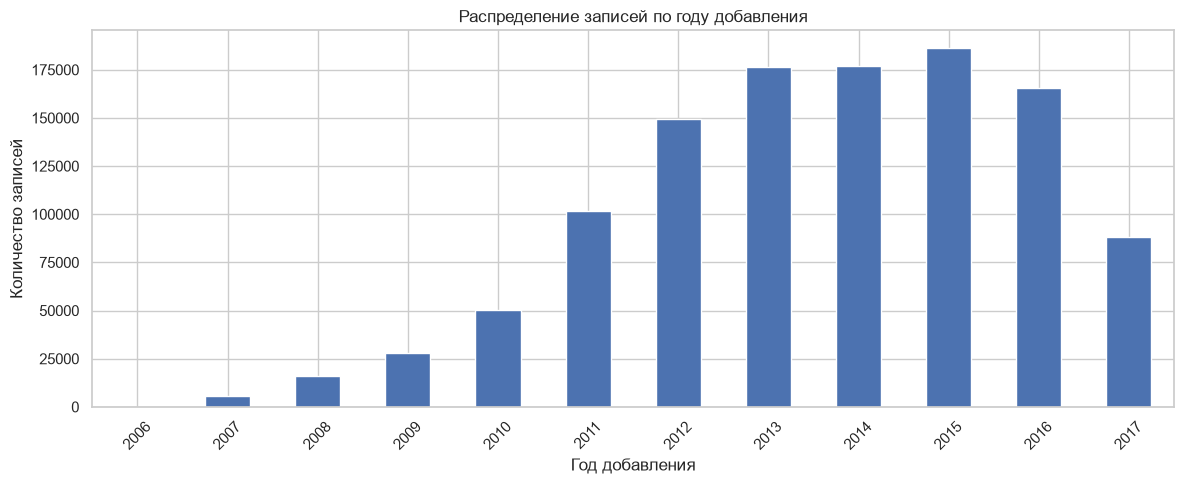

In [43]:
if not added_year_counts.empty:
    ax = added_year_counts.plot.bar(
        figsize=(12, 5),
        color="#4C72B0",
    )

    ax.set(
        title="Распределение записей по году добавления",
        xlabel="Год добавления",
        ylabel="Количество записей",
    )

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Нет распознанных дат для построения графика.")

### 4.7. Выводы по оценкам и временным характеристикам

**Корректность оценок**

Преобразование пользовательских оценок в числовой формат
выполнено без ошибок. Обнаружены 1 106 569 корректных оценок
по шкале от 1 до 5, что составляет 96,74% записей.
В 37 318 записях (3,26%) оценка отсутствует.

Нечисловые заполненные значения и числа вне допустимой
шкалы не обнаружены. Отсутствующие оценки сохраняются
как пропуски и не интерпретируются как отрицательные.

**Оценки в повторных парах**

Исследованы все 2 251 повторные пары пользователя
и произведения, содержащие 4 574 записи.

В 1 595 парах (70,86%) все оценки заполнены и совпадают.
В 241 паре (10,71%) присутствуют пропуски, но среди
заполненных оценок нет расхождений.
В 394 парах (17,50%) обнаружены разные оценки без пропусков.
В 21 паре (0,93%) все оценки отсутствуют.

Таким образом, повторные записи нельзя обрабатывать
простым сохранением произвольной строки. В зависимости
от группы это может привести к потере оценки или изменению
предпочтения, представленного в данных.

Причины расхождений пока не установлены. Разные оценки
могут отражать особенности источника или разные события,
поэтому автоматически считать их ошибками нельзя.

**Преобразование дат**

Все непустые значения временных полей успешно преобразованы
по проверяемому формату.

Поле date_added распознано для всех 1 143 887 записей.
Поле started_at распознано для 796 392 записей,
read_at для 1 031 765 записей. Остальные значения этих
двух полей являются исходными пропусками.

Отсутствие ошибок преобразования не подтверждает
правдоподобность дат. Диапазон started_at составляет
от 01.01.1916 до 25.01.4732, диапазон read_at
от 01.01.0101 до 25.01.4732.

Годы 0101 и 4732 свидетельствуют о наличии неправдоподобных
значений. Необходимо определить количество таких записей,
изучить исходные значения и обосновать правила обработки.
На данном этапе даты и строки не исправлялись и не удалялись.

**Соотношение временных полей**

В 11 записях завершение чтения указано раньше его начала.
Это составляет 0,0014% от 783 842 записей с обеими
распознанными датами. Такие случаи требуют отдельного
разбора; они не считаются автоматически ошибочными.

В 113 122 записях завершение чтения предшествует добавлению
записи, что составляет 10,9639% сравнимых наблюдений.
В 484 051 записи начало чтения следует после добавления,
что составляет 60,7805% сравнимых наблюдений.

Эти два порядка событий могут быть объяснимы:
пользователь способен добавить уже прочитанную книгу
либо сохранить книгу до начала чтения.

Показатели рассчитаны по распознанным датам до проверки
их правдоподобности. После определения правил обработки
подозрительных дат соответствующие сравнения следует повторить.

**Временное распределение**

Даты добавления записей находятся в диапазоне
от 29.08.2006 до 29.10.2017. Максимальное число записей
приходится на 2015 год: 186 077.

Данные за 2017 год заканчиваются в октябре, поэтому
его количество записей нельзя напрямую интерпретировать
как результат полного календарного года. Распределение
характеризует исследуемую выборку и не позволяет делать
выводы об активности всей платформы.

**Ограничения дальнейшей оценки**

Дата добавления записи не гарантирует, что пользовательская
оценка уже существовала в этот момент. Дата завершения чтения
также не является подтверждённым временем выставления оценки.

Поэтому временное разделение по доступным полям требует
явных допущений. Использование итоговой оценки с более
ранней датой добавления может создавать утечку информации.

Следующим шагом необходимо исследовать подозрительные даты
и неоднозначность временного порядка повторных записей.
После этого будут определены правила обработки взаимодействий
и ограничения протокола оценки рекомендательных моделей.

## 5. Подозрительные даты и неоднозначность повторных записей

Цель этапа: определить распространённость подозрительных дат
и проверить, позволяет ли дата добавления однозначно упорядочить
повторные записи пользователя о произведении.

Для предварительной проверки используется конец 2017 года,
соответствующий указанному периоду сбора данных. Это рабочая
граница аудита, а не подтверждённая точная дата выгрузки.

Даты раньше 1900 года рассматриваются отдельно как требующие
проверки. Нижняя граница не используется для автоматического
удаления записей.

Исходные значения сохраняются. Подозрительная дата сама по себе
не является основанием для удаления взаимодействия.

### 5.1. Проверка временных границ

Для каждого временного поля подсчитаем даты раньше 1900 года
и после 2017 года. Доли рассчитываются среди распознанных дат.

Выбранные границы служат для диагностики и не подтверждают
достоверность всех дат внутри интервала.

In [44]:
AUDIT_MIN_YEAR = 1900
AUDIT_MAX_YEAR = 2017

date_flags = pd.DataFrame(index=interactions_audit.index)
date_boundary_rows = []

for column in date_columns:
    dates = interactions_audit[f"{column}_dt"]
    years = dates.dt.year

    early_mask = years.lt(AUDIT_MIN_YEAR).fillna(False)
    late_mask = years.gt(AUDIT_MAX_YEAR).fillna(False)

    date_flags[f"{column}_early"] = early_mask
    date_flags[f"{column}_late"] = late_mask

    recognized_count = int(dates.notna().sum())

    date_boundary_rows.append(
        {
            "Поле": column,
            "Распознано дат": recognized_count,
            "Раньше 1900 года": int(early_mask.sum()),
            "После 2017 года": int(late_mask.sum()),
            "За границами, %": (
                round(
                    (early_mask | late_mask).sum()
                    / recognized_count * 100,
                    4,
                )
                if recognized_count
                else float("nan")
            ),
        }
    )

date_boundary_report = pd.DataFrame(date_boundary_rows)

date_boundary_report

,Поле,Распознано дат,Раньше 1900 года,После 2017 года,"За границами, %"
0,date_added,1143887,0,0,0.0000
1,started_at,796392,0,1,0.0001
2,read_at,1031765,1,1,0.0002


### 5.2. Значения за пределами контрольного интервала

Рассмотрим наиболее частые исходные значения подозрительных дат.
Проверка позволит выявить повторяющиеся шаблоны ошибок.

In [45]:
suspicious_date_rows = []

for column in date_columns:
    suspicious_mask = (
        date_flags[f"{column}_early"]
        | date_flags[f"{column}_late"]
    )

    counts = (
        interactions_audit.loc[suspicious_mask, column]
        .value_counts()
        .head(15)
    )

    for value, count in counts.items():
        suspicious_date_rows.append(
            {
                "Поле": column,
                "Исходная дата": value,
                "Количество": int(count),
            }
        )

pd.DataFrame(
    suspicious_date_rows,
    columns=["Поле", "Исходная дата", "Количество"],
)

,Поле,Исходная дата,Количество
0,started_at,4732-01-25 00:00:00.000,1
1,read_at,0101-01-01 00:00:00.000,1
2,read_at,4732-01-25 00:00:00.000,1


In [46]:
suspicious_any_mask = date_flags.any(axis=1)

interactions_audit.loc[
    suspicious_any_mask,
    [
        "review_id",
        "user_id",
        "work_id",
        "rating_numeric",
        "date_added",
        "started_at",
        "read_at",
    ],
].head(20)

,review_id,user_id,work_id,rating_numeric,date_added,started_at,read_at
205141,e610ee114c95a46e43299a34452cc1a2,fedc9f09c5c0579a2d82d7c71e528c95,6818939,4,2016-07-01 00:00:00.000,,0101-01-01 00:00:00.000
1030547,f4e5721abce1fc2dcb59a7df93e02380,1593dc378382a7953553fec976c0fe93,21580644,1,2017-01-24 00:00:00.000,4732-01-25 00:00:00.000,4732-01-25 00:00:00.000


In [47]:
pd.Series(
    {
        "Записи с подозрительными датами": int(
            suspicious_any_mask.sum()
        ),
        "Из них с корректной оценкой": int(
            (
                suspicious_any_mask
                & interactions_audit["rating_numeric"].notna()
            ).sum()
        ),
    },
    name="Количество",
).to_frame()

,Количество
Записи с подозрительными датами,2
Из них с корректной оценкой,2


### 5.3. Временные поля в пределах контрольного интервала

Создадим отдельную таблицу дат для диагностических расчётов.
Значения за выбранными границами заменяются на NaT только
в этой таблице.

Исходные даты, оценки и строки взаимодействий сохраняются.
Даты внутри интервала не считаются автоматически достоверными.

In [48]:
dates_for_analysis = pd.DataFrame(
    index=interactions_audit.index
)

for column in date_columns:
    suspicious_mask = (
        date_flags[f"{column}_early"]
        | date_flags[f"{column}_late"]
    )

    dates_for_analysis[column] = (
        interactions_audit[f"{column}_dt"]
        .mask(suspicious_mask)
    )

dates_for_analysis.agg(["count", "min", "max"])

,date_added,started_at,read_at
count,1143887,796391,1031763
min,2006-08-29 00:00:00,1916-01-01 00:00:00,1915-05-26 00:00:00
max,2017-10-29 00:00:00,2017-12-29 00:00:00,2017-12-31 00:00:00


In [49]:
comparable_reading_dates = (
    dates_for_analysis["started_at"].notna()
    & dates_for_analysis["read_at"].notna()
)

reading_order_issue = (
    comparable_reading_dates
    & (
        dates_for_analysis["read_at"]
        < dates_for_analysis["started_at"]
    )
)

pd.Series(
    {
        "Записи с обеими датами в интервале": int(
            comparable_reading_dates.sum()
        ),
        "Завершение раньше начала": int(
            reading_order_issue.sum()
        ),
    },
    name="Количество",
).to_frame()

,Количество
Записи с обеими датами в интервале,783841
Завершение раньше начала,11


### 5.4. Совпадающие даты в повторных парах

Проверим, встречается ли несколько записей одной пары
с одинаковой распознанной датой добавления.

Совпадение даты не доказывает одновременность событий:
точность сохранённых временных данных может быть ограничена.

In [50]:
repeated_with_dates = interactions_audit.merge(
    repeated_pairs.reset_index(),
    on=["user_id", "work_id"],
    how="inner",
    validate="many_to_one",
)

same_date_groups = (
    repeated_with_dates
    .dropna(subset=["date_added_dt"])
    .groupby(
        ["user_id", "work_id", "date_added_dt"],
        sort=False,
    )
    .agg(
        records=("review_id", "size"),
        distinct_ratings=("rating_numeric", "nunique"),
    )
    .reset_index()
)

same_date_groups = same_date_groups.loc[
    same_date_groups["records"] > 1
]

pd.Series(
    {
        "Группы с одинаковой датой": len(same_date_groups),
        "Пары хотя бы с одной такой группой": (
            same_date_groups[["user_id", "work_id"]]
            .drop_duplicates()
            .shape[0]
        ),
        "Группы с одинаковой датой и разными оценками": int(
            (same_date_groups["distinct_ratings"] > 1).sum()
        ),
    },
    name="Количество",
).to_frame()

,Количество
Группы с одинаковой датой,33
Пары хотя бы с одной такой группой,33
Группы с одинаковой датой и разными оценками,5


### 5.5. Однозначность последней записи

Для каждой повторной пары найдём максимальную дату добавления
и все записи с этой датой.

Проверим, существует ли единственная последняя запись
и содержит ли она оценку. Эта диагностика не подтверждает,
что дата добавления является временем выставления оценки.

In [51]:
latest_date = (
    repeated_with_dates
    .groupby(["user_id", "work_id"])["date_added_dt"]
    .transform("max")
)

latest_rows = repeated_with_dates.loc[
    repeated_with_dates["date_added_dt"].eq(latest_date)
]

latest_summary = (
    latest_rows
    .groupby(["user_id", "work_id"], sort=False)
    .agg(
        latest_records=("review_id", "size"),
        latest_rated_records=("rating_numeric", "count"),
        latest_distinct_ratings=("rating_numeric", "nunique"),
    )
    .reset_index()
)

latest_summary = latest_summary.merge(
    repeated_rating_summary[
        ["user_id", "work_id", "rated_records"]
    ],
    on=["user_id", "work_id"],
    how="left",
    validate="one_to_one",
)

latest_report = pd.Series(
    {
        "Повторные пары всего": len(repeated_rating_summary),
        "Пары с распознанной датой добавления": len(latest_summary),
        "Пары с единственной последней записью": int(
            latest_summary["latest_records"].eq(1).sum()
        ),
        "Пары с несколькими последними записями": int(
            latest_summary["latest_records"].gt(1).sum()
        ),
        "Пары с разными оценками на последнюю дату": int(
            latest_summary["latest_distinct_ratings"].gt(1).sum()
        ),
        "На последнюю дату оценок нет, ранее оценка была": int(
            (
                latest_summary["latest_rated_records"].eq(0)
                & latest_summary["rated_records"].gt(0)
            ).sum()
        ),
    },
    name="Количество пар",
)

latest_report.to_frame()

,Количество пар
Повторные пары всего,2251
Пары с распознанной датой добавления,2251
Пары с единственной последней записью,2222
Пары с несколькими последними записями,29
Пары с разными оценками на последнюю дату,5
"На последнюю дату оценок нет, ранее оценка была",134


### 5.6. Выводы по подозрительным датам и повторным записям

**Даты за пределами контрольного интервала**

При проверке интервала с 1900 по 2017 год включительно
обнаружены три подозрительных значения в двух взаимодействиях.

В одной записи read_at содержит дату 01.01.0101.
В другой записи started_at и read_at содержат дату 25.01.4732.
Обе записи имеют допустимые по шкале оценки: 4 и 1 соответственно.
В поле date_added значений за выбранными границами не обнаружено.

Годы 0101 и 4732 явно неправдоподобны для пользовательских
событий чтения. Восстановить правильные даты по имеющимся
сведениям невозможно.

Принято решение исключить эти два взаимодействия при формировании
очищенного набора данных. Их доля составляет около 0,000175%
от 1 143 887 исходных записей. Исключение связано с недостоверностью
временных значений и не означает, что сами оценки признаны ошибочными.

После удаления будет проверено изменение количества строк,
уникальных пользователей и произведений. Исходные файлы
останутся без изменений. На текущем диагностическом этапе
строки ещё не удалены: подозрительные даты заменены на NaT
только в таблице dates_for_analysis.

**Ограничения проверки временных границ**

После исключения крайних значений из диагностических расчётов
минимальная дата начала чтения составляет 01.01.1916,
завершения чтения 26.05.1915. Максимальные даты составляют
29.12.2017 и 31.12.2017 соответственно.

Попадание в контрольный интервал не подтверждает достоверность
даты. Границы использованы для предварительной диагностики,
а конец 2017 года не является установленной точной датой выгрузки.

Решение об удалении относится только к двум обнаруженным
взаимодействиям с годами 0101 и 4732. Оно не распространяется
автоматически на другие старые даты или на события чтения,
произошедшие позже добавления записи.

**Несогласованность дат чтения**

После исключения дат за контрольными границами обе даты чтения
доступны для сравнения в 783 841 взаимодействии.

В 11 записях завершение чтения по-прежнему предшествует началу.
Следовательно, эти случаи не объясняются обнаруженными
экстремальными годами.

Такие записи следует отмечать отдельным признаком.
Их даты не следует использовать для обычного расчёта
продолжительности чтения. Оснований автоматически удалять
эти взаимодействия на данном этапе не установлено.

**Совпадающие даты повторных записей**

Обнаружены 33 группы с одинаковой датой добавления внутри
одной пары пользователя и произведения. Они относятся
к 33 различным парам.

В пяти таких группах присутствуют разные заполненные оценки.
Следовательно, дата добавления не всегда позволяет определить
однозначный порядок записей.

Совпадающая дата не доказывает одновременность исходных событий:
точность сохранённых временных данных может быть ограничена.

**Проверка выбора последней записи**

Для всех 2 251 повторной пары имеется распознанная дата добавления.
В 2 222 парах максимальной дате соответствует одна запись.
В 29 парах на максимальную дату приходится несколько записей,
в том числе в пяти парах с различными оценками.

В 134 парах все записи на максимальную дату не содержат оценки,
хотя в записях с более ранней датой заполненная оценка имеется.
Поэтому сохранение только последней записи привело бы
к потере имеющейся информации об оценке для этих пар.

Автоматический выбор последней строки или произвольной записи
с максимальной датой не применяется.

**Решения по дальнейшей обработке**

При формировании очищенного набора будут исключены два
взаимодействия с явно неправдоподобными годами чтения.
Результат удаления будет проверен по количеству строк,
пользователей и произведений.

Остальные выявленные особенности не приводят к автоматическому
удалению записей. Случаи завершения чтения раньше начала
будут отмечены отдельно.

Правило сведения повторных взаимодействий к одной записи
будет определено при формировании модельной выборки.
Оно должно соответствовать постановке задачи и протоколу
оценки, а при временном разделении учитывать доступность
информации относительно границы обучения.

Дата добавления записи не считается подтверждённым временем
выставления оценки. Это ограничение сохраняется независимо
от выбранного способа обработки повторов.

## 6. Проверка ISBN в каталогах книг

Цель этапа: оценить пригодность ISBN для сопоставления
двух каталогов.

ISBN идентифицирует издание книги. Разные издания одного
произведения могут иметь разные ISBN, поэтому отсутствие
совпадения не доказывает, что произведения различаются.

Проверяются заполненность, формат, контрольная цифра
и повторяемость идентификаторов после нормализации.

Исходные столбцы сохраняются. Автоматическое восстановление
повреждённых ISBN и объединение каталогов на этом этапе
не выполняются.

### 6.1. Нормализация представления

Для диагностики удалим пробельные символы и обычные дефисы,
а буквы приведём к верхнему регистру.

Нормализация изменяет только представление идентификатора.
Недостающие цифры не восстанавливаются, контрольная цифра
не пересчитывается.

In [52]:
def normalize_isbn(series):
    values = (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"[\s-]+", "", regex=True)
    )

    return values.mask(values.eq(""), pd.NA)


isbn_sources = {
    "books_texts.isbn": books_texts["isbn"],
    "books_metadata.isbn": books_metadata["isbn"],
    "books_metadata.isbn13": books_metadata["isbn13"],
}

isbn_normalized = {
    name: normalize_isbn(series)
    for name, series in isbn_sources.items()
}

### 6.2. Совместная заполненность идентификаторов

Определим, сколько произведений имеют оба идентификатора,
только один из них или не имеют ни одного.

На этом шаге учитывается наличие значения, а не его корректность.

In [53]:
has_isbn = isbn_normalized["books_metadata.isbn"].notna()
has_isbn13 = isbn_normalized["books_metadata.isbn13"].notna()

isbn_availability = pd.DataFrame(
    {
        "Состояние": [
            "Заполнены оба поля",
            "Заполнено только isbn",
            "Заполнено только isbn13",
            "Оба поля отсутствуют",
        ],
        "Количество": [
            int((has_isbn & has_isbn13).sum()),
            int((has_isbn & ~has_isbn13).sum()),
            int((~has_isbn & has_isbn13).sum()),
            int((~has_isbn & ~has_isbn13).sum()),
        ],
    }
)

isbn_availability["Доля, %"] = (
    isbn_availability["Количество"]
    / len(books_metadata)
    * 100
).round(2)

isbn_availability

,Состояние,Количество,"Доля, %"
0,Заполнены оба поля,11459,84.72
1,Заполнено только isbn,15,0.11
2,Заполнено только isbn13,405,2.99
3,Оба поля отсутствуют,1646,12.17


### 6.3. Длина идентификаторов

Рассмотрим длину непустых значений после удаления разделителей.
Стандартные длины ISBN составляют 10 и 13 символов.

Подходящая длина является необходимым, но недостаточным
условием корректности.

In [54]:
isbn_length_rows = []

for name, values in isbn_normalized.items():
    lengths = (
        values.dropna()
        .str.len()
        .value_counts()
        .sort_index()
    )

    for length, count in lengths.items():
        isbn_length_rows.append(
            {
                "Источник": name,
                "Длина": int(length),
                "Количество": int(count),
            }
        )

isbn_length_report = pd.DataFrame(isbn_length_rows)

isbn_length_report

,Источник,Длина,Количество
0,books_texts.isbn,3,1
1,books_texts.isbn,5,4
2,books_texts.isbn,6,3
3,books_texts.isbn,7,467
4,books_texts.isbn,8,2957
5,books_texts.isbn,9,42634
6,books_texts.isbn,10,39451
7,books_texts.isbn,12,1
8,books_metadata.isbn,9,2
9,books_metadata.isbn,10,11472


### 6.4. Формат и контрольная цифра

Для ISBN-10 проверим девять начальных цифр, допустимость
последнего символа и контрольную сумму.

Для ISBN-13 проверим цифровой формат, префикс 978 или 979
и контрольную сумму.

Успешная проверка означает формальную корректность номера,
но не подтверждает его принадлежность конкретному изданию.

In [55]:
def classify_isbn(value):
    if pd.isna(value):
        return "Отсутствует"

    if len(value) == 10:
        valid_format = (
            all(char in "0123456789" for char in value[:9])
            and value[-1] in "0123456789X"
        )

        if not valid_format:
            return "Недопустимые символы"

        digits = [
            10 if char == "X" else int(char)
            for char in value
        ]

        checksum = sum(
            digit * weight
            for digit, weight in zip(digits, range(10, 0, -1))
        )

        if checksum % 11 == 0:
            return "Корректный ISBN-10"

        return "Ошибка контрольной цифры"

    if len(value) == 13:
        if not all(char in "0123456789" for char in value):
            return "Недопустимые символы"

        if not value.startswith(("978", "979")):
            return "Недопустимый префикс ISBN-13"

        checksum = sum(
            int(char) * (1 if position % 2 == 0 else 3)
            for position, char in enumerate(value)
        )

        if checksum % 10 == 0:
            return "Корректный ISBN-13"

        return "Ошибка контрольной цифры"

    return "Нестандартная длина"

In [56]:
isbn_checks = {}

for name, values in isbn_normalized.items():
    isbn_checks[name] = pd.DataFrame(
        {
            "original": isbn_sources[name],
            "normalized": values,
            "status": values.apply(classify_isbn),
        }
    )

isbn_status_rows = []

for name, table in isbn_checks.items():
    counts = table["status"].value_counts()

    for status, count in counts.items():
        isbn_status_rows.append(
            {
                "Источник": name,
                "Статус": status,
                "Количество": int(count),
                "Доля, %": round(count / len(table) * 100, 2),
            }
        )

isbn_status_report = pd.DataFrame(isbn_status_rows)

isbn_status_report

,Источник,Статус,Количество,"Доля, %"
0,books_texts.isbn,Нестандартная длина,46067,46.07
1,books_texts.isbn,Корректный ISBN-10,39012,39.01
2,books_texts.isbn,Отсутствует,14482,14.48
3,books_texts.isbn,Ошибка контрольной цифры,401,0.40
4,books_texts.isbn,Недопустимые символы,38,0.04
5,books_metadata.isbn,Корректный ISBN-10,11452,84.67
6,books_metadata.isbn,Отсутствует,2051,15.16
7,books_metadata.isbn,Ошибка контрольной цифры,20,0.15
8,books_metadata.isbn,Нестандартная длина,2,0.01
9,books_metadata.isbn13,Корректный ISBN-13,11804,87.28


In [57]:
valid_isbn_statuses = [
    "Корректный ISBN-10",
    "Корректный ISBN-13",
]

isbn_problem_examples = []

for name, table in isbn_checks.items():
    problem_mask = ~table["status"].isin(
        valid_isbn_statuses + ["Отсутствует"]
    )

    examples = (
        table.loc[problem_mask]
        .groupby("status", sort=False)
        .head(5)
        .copy()
    )

    examples.insert(0, "Источник", name)
    isbn_problem_examples.append(examples)

pd.concat(isbn_problem_examples, ignore_index=True)

,Источник,original,normalized,status
0,books_texts.isbn,948984147,948984147,Нестандартная длина
1,books_texts.isbn,814327079,814327079,Нестандартная длина
2,books_texts.isbn,875848419,875848419,Нестандартная длина
3,books_texts.isbn,393009076,393009076,Нестандартная длина
4,books_texts.isbn,752456830,752456830,Нестандартная длина
5,books_texts.isbn,9780980668,9780980668,Ошибка контрольной цифры
6,books_texts.isbn,6054173259,6054173259,Ошибка контрольной цифры
7,books_texts.isbn,9780908244,9780908244,Ошибка контрольной цифры
8,books_texts.isbn,8423992010,8423992010,Ошибка контрольной цифры
9,books_texts.isbn,9380658674,9380658674,Ошибка контрольной цифры


### 6.5. Повторы после нормализации

Проверим повторяемость непустых ISBN после удаления разделителей.

Отдельно подсчитаем повторы среди формально корректных номеров.
Нормализация может выявить совпадения, которые не были заметны
при сравнении исходных строк.

In [58]:
isbn_duplicate_rows = []

for name, table in isbn_checks.items():
    nonempty = table.loc[
        table["normalized"].notna(),
        "normalized",
    ]

    valid = table.loc[
        table["status"].isin(valid_isbn_statuses),
        "normalized",
    ]

    isbn_duplicate_rows.append(
        {
            "Источник": name,
            "Непустых значений": len(nonempty),
            "Уникальных непустых": nonempty.nunique(),
            "Повторов сверх первого": int(
                nonempty.duplicated().sum()
            ),
            "Корректных значений": len(valid),
            "Повторов среди корректных": int(
                valid.duplicated().sum()
            ),
        }
    )

isbn_duplicate_report = pd.DataFrame(isbn_duplicate_rows)

isbn_duplicate_report

,Источник,Непустых значений,Уникальных непустых,Повторов сверх первого,Корректных значений,Повторов среди корректных
0,books_texts.isbn,85518,85518,0,39012,0
1,books_metadata.isbn,11474,11474,0,11452,0
2,books_metadata.isbn13,11864,11864,0,11804,0


### 6.6. Выводы по проверке ISBN

**Совместная заполненность идентификаторов**

В таблице метаданных 11 459 произведений имеют оба заполненных
поля isbn и isbn13, что составляет 84,72% записей.
Только isbn заполнено у 15 произведений (0,11%),
только isbn13 у 405 произведений (2,99%).

Оба идентификатора отсутствуют у 1 646 произведений (12,17%).
Следовательно, хотя бы одно поле заполнено у 11 879 произведений.
При этом наличие значения ещё не подтверждает его корректность.

Произведения без ISBN не исключаются из основного каталога:
они уже связаны с пользовательскими взаимодействиями через work_id.
Отсутствие ISBN ограничивает возможности сопоставления
с дополнительным источником, но не делает остальные сведения
о произведении непригодными.

**Качество ISBN первого каталога**

В books_texts формальную проверку ISBN-10 прошли 39 012 значений,
что составляет 39,01% всех записей каталога.
ISBN отсутствует в 14 482 записях (14,48%).

Нестандартная длина обнаружена у 46 067 значений (46,07%).
Из них 42 634 имеют длину 9 символов. Также встречаются
значения длиной 3, 5, 6, 7, 8 и 12 символов.

Преобладание девятисимвольных значений позволяет предположить
потерю ведущих нулей при подготовке источника. Однако эта причина
пока не подтверждена. Автоматическое дополнение всех коротких
значений нулями не выполнялось.

У 401 десятисимвольного значения обнаружена ошибка контрольной
цифры, у 38 недопустимые символы. Среди примеров присутствуют
значения, не соответствующие структуре ISBN.

Всего 46 506 заполненных значений первого каталога не прошли
формальную проверку. Использовать их как надёжные ключи
объединения без дополнительной обработки нельзя.

**Качество идентификаторов в метаданных**

В поле isbn формальную проверку ISBN-10 прошли 11 452 значения
(84,67% всех записей метаданных). Отсутствуют 2 051 значение,
у 20 обнаружена ошибка контрольной цифры,
ещё два значения имеют длину 9 символов.

В поле isbn13 формальную проверку ISBN-13 прошли 11 804 значения
(87,28%). Отсутствуют 1 661 значение.
У 50 тринадцатисимвольных значений обнаружен недопустимый
для ISBN-13 префикс.

Категория ошибки контрольной цифры содержит шесть значений
поля isbn13. Два из них имеют длину 10 символов и проверялись
универсальной функцией как кандидаты ISBN-10. Они также
не соответствуют ожидаемой длине поля isbn13.
Ещё четыре значения имеют нестандартную длину 11 или 12 символов.

В сумме 60 заполненных значений поля isbn13 не прошли проверку.
Число произведений, имеющих хотя бы один корректный идентификатор,
пока отдельно не рассчитано: результаты проверки двух полей
нельзя складывать из-за их пересечения.

**Повторяемость идентификаторов**

После удаления пробельных символов и обычных дефисов,
а также приведения букв к верхнему регистру повторы
не обнаружены ни в одном из трёх проверяемых столбцов.

В первом каталоге уникальны все 85 518 непустых значений.
В метаданных уникальны 11 474 непустых значения isbn
и 11 864 непустых значения isbn13.

Повторы среди формально корректных номеров также отсутствуют.
Эти результаты относятся к сравнению нормализованных строк.
Эквивалентность ISBN-10 и ISBN-13 пока не проверялась.
После преобразования к общему представлению и возможного
восстановления номеров проверку повторов потребуется выполнить
повторно.

**Ограничения и дальнейшие действия**

Успешная проверка формата и контрольной цифры не подтверждает,
что ISBN действительно принадлежит указанной книге.
Кроме того, ISBN относится к изданию: разные издания одного
произведения могут иметь разные номера.

Перед сопоставлением каталогов необходимо проверить гипотезу
потери ведущих нулей, подготовить общее представление ISBN-13
и проверить согласованность полей isbn и isbn13 в метаданных.

После этого следует оценить количество однозначных соответствий,
проверить названия и авторов сопоставленных записей и определить,
какую информацию дополнительный каталог может предоставить
для основного набора произведений.

На данном этапе исходные идентификаторы сохранены.
Восстановление номеров, удаление книг и объединение каталогов
не выполнялись.